# RQ1: Sunshine duration vs chart valence, by season

**Question:** How does the daily duration of sunshine (hours) correlate with the average **valence** (musical positivity) of the German Spotify Top 200, and does this relationship vary by season?

Reporting layer over the `Workflow 1` Snakemake outputs: it reads the results and adds interpretation. The analysis itself lives in the tested components under `src/Workflow 1/`.

## Method (in brief)

1. Aggregate the charts to a **daily** audio profile (mean of each feature) together with that day's weather (`utils.aggregate_daily`).
2. Label each day with its **meteorological season** (winter = DJF, spring = MAM, summer = JJA, autumn = SON), the same mapping used by the shared `dataprocessing.py` step.
3. Compute the **Spearman rank correlation** between daily sunshine hours and mean valence, once over the whole 2017-2021 window ("all") and once per season. Spearman is used (consistent with Workflow 2) because daily sunshine is skewed and bounded, and no linearity is assumed.
4. Visualise the relationship as a 2x2 grid of per-season scatter plots with least-squares trend lines, annotated with each season's rho and p-value.

## How to reproduce

```bash
cd "src/Workflow 1"
snakemake -s SnakefileWorkflow1 --cores 1
```

This regenerates `results/workflow_1/sunshine_valence_correlation.csv` and `sunshine_valence_by_season.png`, which the cells below load.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

RESULTS = Path("..") / "results" / "workflow_1"
corr = pd.read_csv(RESULTS / "sunshine_valence_correlation.csv")
corr

,group,n_days,rho,p_value,significant
0,all,1826,0.054357,0.020184,True
1,winter,451,0.091564,0.051990,False
2,spring,460,-0.025055,0.591970,False
3,summer,460,-0.021613,0.643831,False
4,autumn,455,-0.014906,0.751176,False


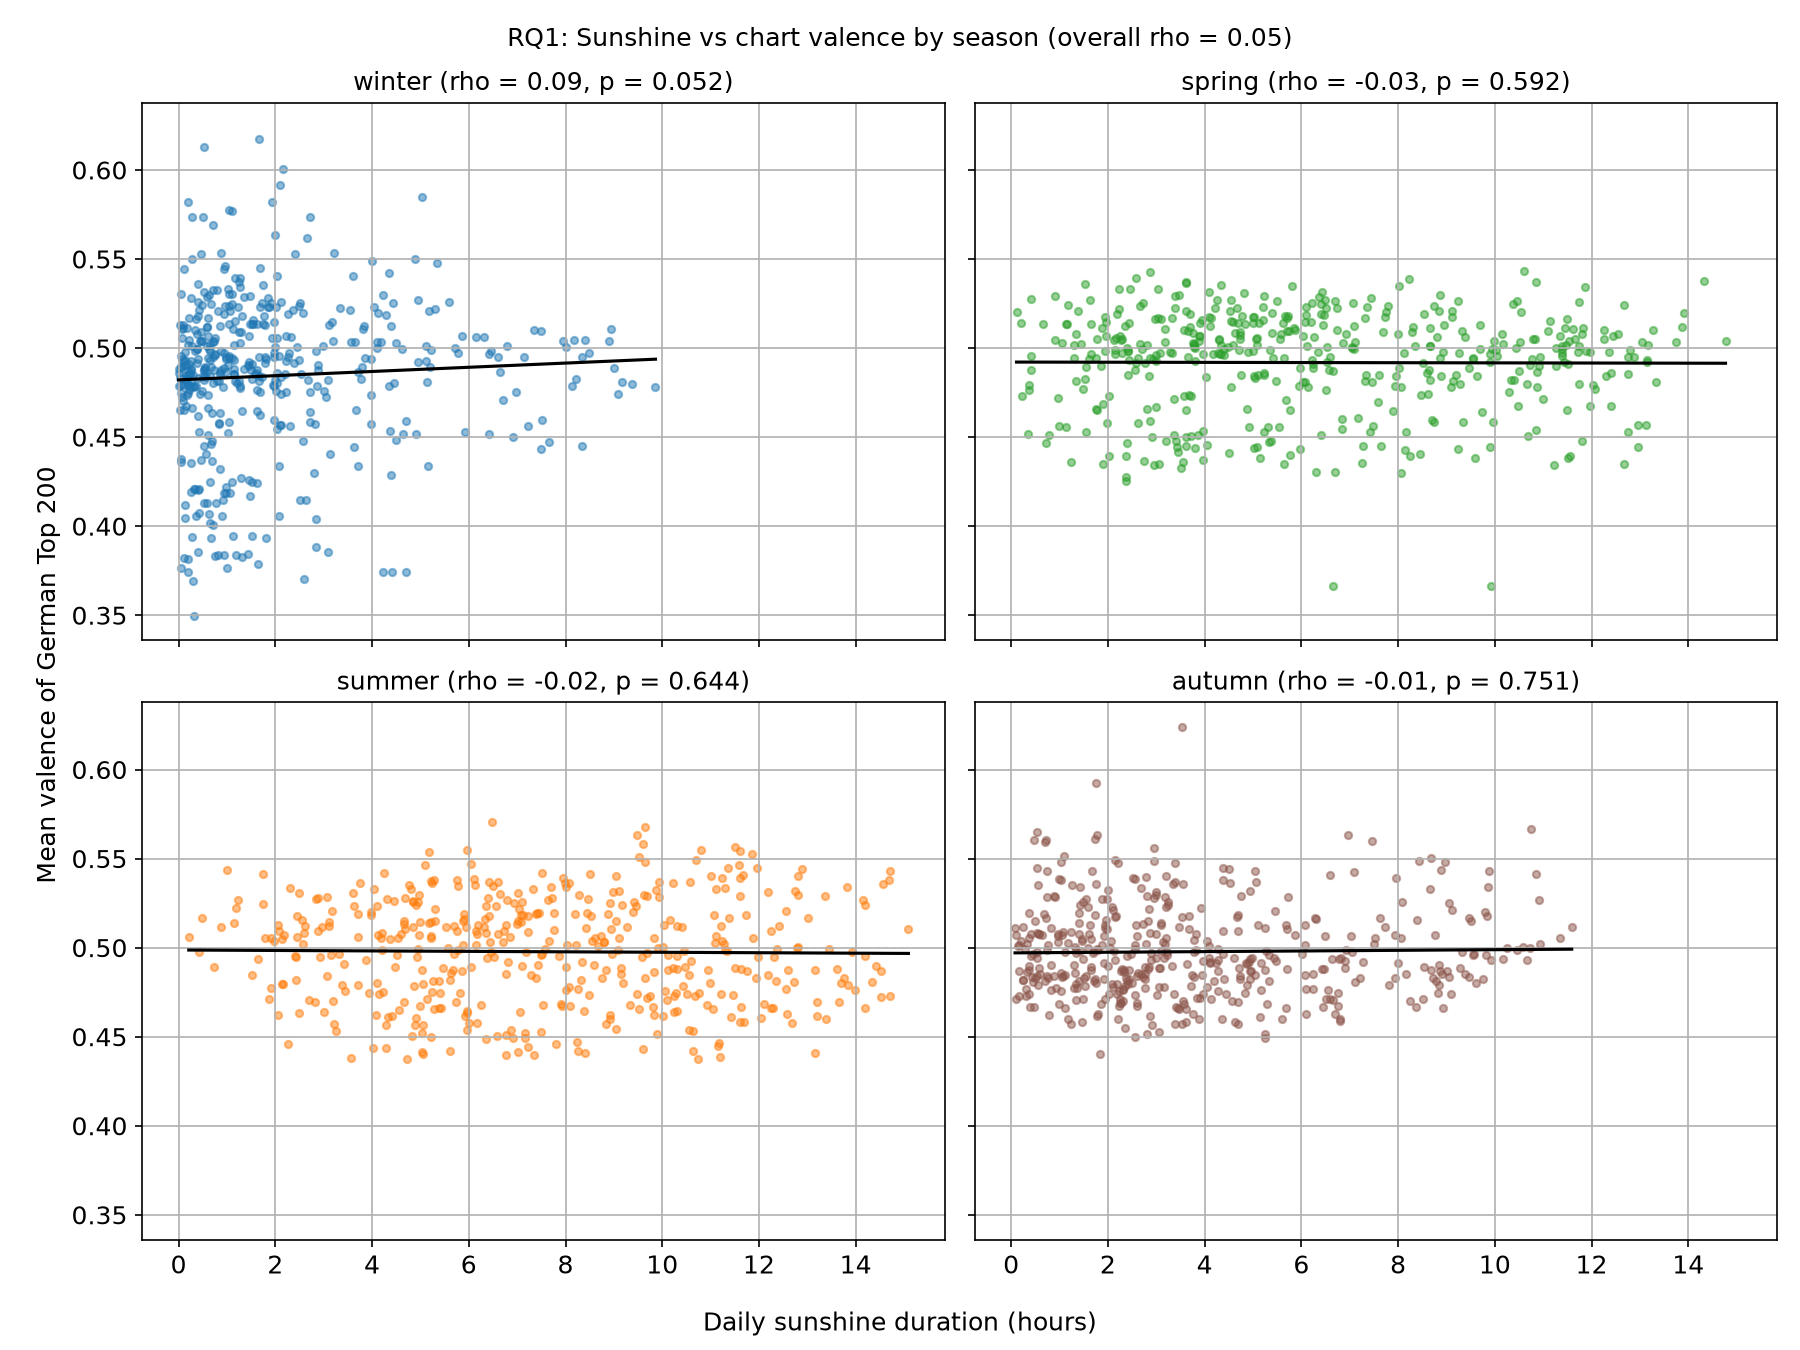

In [2]:
display(Image(filename=str(RESULTS / "sunshine_valence_by_season.png")))

## Findings

- **Overall, sunnier days are very slightly happier-sounding:** across all 1,826 days, sunshine and mean chart valence correlate positively but weakly (rho = 0.054, p = 0.020).
- **Within seasons the relationship disappears.** No individual season shows a significant correlation: winter rho = 0.09 (p = 0.052, borderline), spring rho = -0.03, summer rho = -0.02, autumn rho = -0.01 (all p > 0.5).
- **The overall correlation is therefore mostly a between-season effect:** summer days have both more sunshine and (slightly) happier charts than winter days, which creates a small pooled correlation even though *within* any given season, a sunnier-than-usual day does not come with happier music.
- The only hint of a genuine within-season signal is **winter**, where the trend is positive and just misses significance -- plausibly because sunshine varies most dramatically relative to its (low) winter baseline.

## Caveats

- **Season is a confound for the pooled estimate** -- this is exactly why the per-season breakdown is part of the research question, and it changes the answer from "yes, weakly" to "mostly no, once season is controlled". RQ8 tests this formally with a season-baseline model comparison.
- **Chart inertia:** the Top 200 changes slowly from day to day, so consecutive daily observations are not independent; p-values are therefore optimistic.
- **Cultural calendar effects** (Christmas music in December, COVID-19 period) shift valence for reasons unrelated to weather (NFR-12).
- **Aggregation:** the daily valence is the simple mean over the day's charting tracks (not stream-weighted), and sunshine is a national average across DWD stations.

## Takeaway

Daily sunshine duration has only a **weak positive association** with the valence of the German charts (rho = 0.05), and the relationship **does vary by season** -- in the strongest possible sense: it only exists *between* seasons, not within them. Once season is held fixed, a sunnier day does not measurably make Germany's streaming happier; winter shows the closest thing to a real within-season effect. Whether weather carries any predictive signal beyond the seasonal cycle is tested head-on in RQ8.